# RoBERTa - Deteksi Teks AI vs Manusia (CV Transparan + Test 20% + Uji Lintas-Sumber)
Platform: Kaggle T4 GPU

**Desain evaluasi (semua bisa diaudit):**

| Bagian | Isi | Fungsi |
|---|---|---|
| **Test 20%** | Dipisah TOTAL di STEP 4B (disimpan ke `test20.csv`), tidak dipakai untuk training/validasi/pemilihan model | Test independen (dites **sekali**, memakai ensemble 5 model) |
| **5-Fold CV pada 80% (train80)** | Setiap teks dites tepat 1x; val 10% dari bagian train tiap fold dipakai early stopping | Estimasi performa stabil (mean +/- std) + prediksi OOF |
| **Uji lintas-sumber (2 arah)** | Latih pada sumber A, uji pada sumber B yang tidak pernah dilihat | Mengukur generalisasi sebenarnya |
| **Audit kebocoran + baseline TF-IDF** | ID, duplikat, near-duplicate, confound sumber | Bukti transparansi |

Aturan: threshold **tetap 0,5** (tidak dituning pada data uji); library dikunci agar tokenisasi normal; hasil tiap eksperimen disimpan ke disk (bisa dilanjutkan jika sesi putus).

## STEP 1 - Instalasi

In [1]:
!pip install -q accelerate scikit-learn matplotlib seaborn ftfy "transformers==4.46.3" "tokenizers==0.20.3"
import transformers
print('Transformers:', transformers.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.85.7 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Transformers: 4.46.3


## STEP 2 - Import & Konfigurasi

In [2]:
import re, os, gc, json, glob, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ftfy
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_curve, auc)
import torch
from torch.utils.data import Dataset
from transformers import (RobertaTokenizerFast, RobertaForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback)

# ── Konfigurasi ─────────────────────────────────────────────────────────────
SEED        = 42
MODEL_NAME  = 'roberta-base'
MAX_LENGTH  = 512
MIN_WORDS, MAX_WORDS = 50, 450
TEST_SIZE    = 0.20          # data uji 20% (test independen)
N_FOLDS      = 5
VAL_RATIO    = 0.10          # dari bagian train tiap fold (untuk early stopping)
THRESHOLD    = 0.5           # TETAP, tidak dituning

LR, WEIGHT_DECAY, LABEL_SMOOTH = 2e-5, 0.01, 0.05
EPOCHS, PATIENCE = 5, 2
NGPU = max(1, torch.cuda.device_count())
BATCH_DEVICE, GRAD_ACCUM = (8 // NGPU if NGPU > 1 else 8), 4   # batch efektif tetap 32 (1 atau 2 GPU)
WARMUP_RATIO = 0.1
RESUME       = True          # lewati eksperimen yang sudah selesai (aman jika sesi putus)
SAVE_MODELS  = True          # simpan model tiap fold (untuk ensemble/inference)

WORKING_DIR = '/kaggle/working'
SPLIT_DIR = f'{WORKING_DIR}/split_data'
EXP_DIR   = f'{WORKING_DIR}/experiments'
RES_DIR   = f'{WORKING_DIR}/results'
for d in [SPLIT_DIR, EXP_DIR, RES_DIR]: os.makedirs(d, exist_ok=True)

np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| GPU:', torch.cuda.device_count())

Device: cuda | GPU: 2


## STEP 3 - Muat Data

In [3]:
csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)
target = [f for f in csv_files if any(k in f.lower() for k in ['5000','human','machine'])]
DATA_PATH = target[0] if target else csv_files[0]
df = pd.read_csv(DATA_PATH)
print('Dataset:', DATA_PATH, '|', df.shape)
df['orig_row'] = np.arange(len(df))
df['orig_id']  = df['index'] if 'index' in df.columns else df['orig_row']
print(pd.crosstab(df['label'], df['source']))

Dataset: /kaggle/input/datasets/qiransalsabillahmuz/dataset/5000human_5000machine.csv | (10000, 8)
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0    3025       1975
1                2635    2365       0          0


## STEP 4 - Filter & Preprocessing minimal
Jumlah baris yang dibuang dicatat. Tidak ada pemotongan teks berdasarkan kata tertentu.

In [4]:
df['word_count'] = df['text'].astype(str).str.split().str.len()
n0 = len(df)
df = df[(df['word_count'] >= MIN_WORDS) & (df['word_count'] <= MAX_WORDS)].copy()
print(f'Filter {MIN_WORDS}-{MAX_WORDS} kata: {n0:,} -> {len(df):,} (dibuang {n0-len(df)})')

def preprocess_text(t):
    t = ftfy.fix_text(str(t))
    t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'http\S+|www\.\S+', '', t)
    t = re.sub(r'[^\x00-\x7F]+', '', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean_text'] = df['text'].apply(preprocess_text)
n1 = len(df)
df = df[df['clean_text'].str.len() > 10].reset_index(drop=True)
print(f'Teks terlalu pendek dibuang: {n1-len(df)} | Total akhir: {len(df):,}')
print(pd.crosstab(df['label'], df['source']))

Filter 50-450 kata: 10,000 -> 9,778 (dibuang 222)
Teks terlalu pendek dibuang: 0 | Total akhir: 9,778
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0    2898       1922
1                2615    2343       0          0


## STEP 4B - Pemisahan TOTAL Data 80% (training) dan 20% (testing)
Dilakukan sekali, tepat setelah preprocessing. Data 20% disimpan ke `test20.csv` dan tetap ada di `df_test20`, tetapi **tidak** dipakai untuk training, validasi, early stopping, fit TF-IDF, maupun threshold. Dipakai satu kali di STEP 11. Mulai sini `df` hanya berisi data 80%.

In [5]:
df['strata'] = df['label'].astype(str) + '_' + df['source'].astype(str)
df['text_sha1'] = df['clean_text'].apply(lambda s: hashlib.sha1(s.encode('utf-8')).hexdigest())
all_idx = np.arange(len(df))

tr80_idx, te20_idx = train_test_split(all_idx, test_size=TEST_SIZE, random_state=SEED, stratify=df['strata'])
COLS80 = ['orig_id','orig_row','label','source','word_count','clean_text','text_sha1','strata']
df_train80 = df.iloc[np.sort(tr80_idx)][COLS80].reset_index(drop=True)
df_test20  = df.iloc[np.sort(te20_idx)][COLS80].reset_index(drop=True)
df_train80.to_csv(f'{SPLIT_DIR}/train80.csv', index=False)
df_test20.to_csv(f'{SPLIT_DIR}/test20.csv', index=False)

print(f'Total: {len(df):,} | Train 80%: {len(df_train80):,} | Test 20%: {len(df_test20):,}')
print('Irisan orig_id  80%âˆ©20% :', len(set(df_train80['orig_id']) & set(df_test20['orig_id'])), '(harus 0)')
print('Irisan text_sha1 80%âˆ©20%:', len(set(df_train80['text_sha1']) & set(df_test20['text_sha1'])), '(harus 0)')
print('\n=== TRAIN 80% (label x sumber) ===');
print(pd.crosstab(df_train80['label'], df_train80['source']))
print('\n=== TEST 20% (label x sumber) ===')
print(pd.crosstab(df_test20['label'], df_test20['source']))

# Mulai sini df HANYA berisi data 80%. df_test20 tetap ada (jangan di-del).
df = df_train80.copy()

Total: 9,778 | Train 80%: 7,822 | Test 20%: 1,956
Irisan orig_id  80%âˆ©20% : 0 (harus 0)
Irisan text_sha1 80%âˆ©20%: 0 (harus 0)

=== TRAIN 80% (label x sumber) ===
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0    2318       1538
1                2092    1874       0          0

=== TEST 20% (label x sumber) ===
source  Rotten_Tomato  WMT-16  medium  wikipedia
label                                           
0                   0       0     580        384
1                 523     469       0          0


## STEP 5 - Pembagian Data: 5-Fold CV pada Data 80%
Stratifikasi = label Ã -  sumber. Semua pembagian dilakukan **sekali** dan diekspor ke CSV. Data uji 20% sudah dipisah di STEP 4B.

In [6]:
# df = data 80% (dari STEP 4B), kolom 'strata' dan 'text_sha1' sudah ada
dev_idx = np.arange(len(df))
df['split'] = 'dev'

# 5-Fold CV pada seluruh data 80%
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
df['fold'] = 0
fold_sets = {}                                    # k -> (train_idx, val_idx, test_idx)
for k, (a, b) in enumerate(skf.split(dev_idx, df.loc[dev_idx, 'strata']), start=1):
    test_k = dev_idx[b]
    tv_k   = dev_idx[a]
    tr_k, va_k = train_test_split(tv_k, test_size=VAL_RATIO, random_state=SEED + k,
                                  stratify=df.loc[tv_k, 'strata'])
    df.loc[test_k, 'fold'] = k
    fold_sets[k] = (np.sort(tr_k), np.sort(va_k), np.sort(test_k))

# Ekspor
roles = []
for k, (tr, va, te) in fold_sets.items():
    for role, ix in [('train', tr), ('val', va), ('test', te)]:
        roles.append(pd.DataFrame({'fold': k, 'role': role, 'orig_id': df.loc[ix,'orig_id'].values,
                                   'orig_row': df.loc[ix,'orig_row'].values,
                                   'label': df.loc[ix,'label'].values, 'source': df.loc[ix,'source'].values}))
roles = pd.concat(roles, ignore_index=True)
roles.to_csv(f'{SPLIT_DIR}/fold_roles.csv', index=False)
# CSV train/val/test per fold (lengkap dengan teks) -> untuk ditunjukkan ke penguji
COLS = ['orig_id','orig_row','label','source','word_count','clean_text']
for k, (tr, va, te) in fold_sets.items():
    os.makedirs(f'{SPLIT_DIR}/fold{k}', exist_ok=True)
    for role, ix in [('train', tr), ('val', va), ('test', te)]:
        df.loc[ix, COLS].to_csv(f'{SPLIT_DIR}/fold{k}/{role}.csv', index=False)
df[['orig_id','orig_row','split','fold','label','source','word_count','text_sha1']] \
    .to_csv(f'{SPLIT_DIR}/split_manifest.csv', index=False)
df[['orig_id','orig_row','fold','label','source','word_count','clean_text']] \
    .to_csv(f'{SPLIT_DIR}/dev.csv', index=False)
json.dump({'seed':SEED,'test_size':0.20,'n_folds':N_FOLDS,'val_ratio':VAL_RATIO,
           'stratify':'label_source','min_words':MIN_WORDS,'max_words':MAX_WORDS,
           'total_rows':int(len(df) + len(df_test20)),'dev_rows':int(len(dev_idx)),'test_rows':int(len(df_test20)),
           'data_path':DATA_PATH}, open(f'{SPLIT_DIR}/split_config.json','w'), indent=2)

print('Data 80% (CV):', len(dev_idx), '| Test 20% (test20.csv):', len(df_test20))
print('\n=== FOLD x LABEL x SUMBER (data 80%) ===')
print(df.assign(grp='fold'+df['fold'].astype(str))
        .pivot_table(index=['label','source'], columns='grp', values='orig_id', aggfunc='count'))
print('\n=== UKURAN TIAP FOLD (train / val / test) ===')
for k,(tr,va,te) in fold_sets.items(): print(f'  Fold {k}: {len(tr):,} / {len(va):,} / {len(te):,}')
print('\nFile:', sorted(os.listdir(SPLIT_DIR)))

Data 80% (CV): 7822 | Test 20% (test20.csv): 1956

=== FOLD x LABEL x SUMBER (data 80%) ===
grp                  fold1  fold2  fold3  fold4  fold5
label source                                          
0     medium           464    464    464    463    463
      wikipedia        308    307    307    308    308
1     Rotten_Tomato    418    419    419    418    418
      WMT-16           375    375    374    375    375

=== UKURAN TIAP FOLD (train / val / test) ===
  Fold 1: 5,631 / 626 / 1,565
  Fold 2: 5,631 / 626 / 1,565
  Fold 3: 5,632 / 626 / 1,564
  Fold 4: 5,632 / 626 / 1,564
  Fold 5: 5,632 / 626 / 1,564

File: ['dev.csv', 'fold1', 'fold2', 'fold3', 'fold4', 'fold5', 'fold_roles.csv', 'split_config.json', 'split_manifest.csv', 'test20.csv', 'train80.csv']


## STEP 6 - Audit Kebocoran Data

In [7]:
# 1. Data 80% (df) vs Test 20% (df_test20): ID dan hash
print('Irisan ID   80%âˆ©test20        :', len(set(df['orig_id']) & set(df_test20['orig_id'])))
print('Hash sama   80%âˆ©test20        :', len(set(df['text_sha1']) & set(df_test20['text_sha1'])))
print('Duplikat teks persis (80%)    :', int(df['text_sha1'].duplicated().sum()))
print('Duplikat teks persis (test20) :', int(df_test20['text_sha1'].duplicated().sum()))

# 2. Tiap fold: tidak ada irisan train/val/test
ok = True
for k,(tr,va,te) in fold_sets.items():
    inter = len(set(tr)&set(va)) + len(set(tr)&set(te)) + len(set(va)&set(te))
    ok &= (inter == 0)
print('Semua fold bebas irisan train/val/test:', ok)

# 3. Near-duplicate: test20 -> data 80% (TF-IDF cosine; vectorizer di-fit HANYA pada data 80%)
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True)
X80 = vec.fit_transform(df['clean_text'])
X20 = vec.transform(df_test20['clean_text'])
ms = np.zeros(X20.shape[0])
for i in range(0, X20.shape[0], 500):
    sims = X20[i:i+500] @ X80.T
    ms[i:i+500] = sims.max(axis=1).toarray().ravel()
print(f'Kemiripan maks test20->data80: median={np.median(ms):.3f} | P99={np.percentile(ms,99):.3f} | >0.9: {(ms>0.9).sum()}')

Irisan ID   80%âˆ©test20        : 0
Hash sama   80%âˆ©test20        : 0
Duplikat teks persis (80%)    : 0
Duplikat teks persis (test20) : 0
Semua fold bebas irisan train/val/test: True
Kemiripan maks test20->data80: median=0.149 | P99=0.584 | >0.9: 0


## STEP 7 - Diagnostik Confound Sumber (baseline TF-IDF, tanpa transformer)
Di dataset ini sumber tidak muncul di kedua kelas: Human = Medium + Wikipedia, AI = Rotten_Tomato + WMT-16.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
# Vectorizer di-fit HANYA pada data 80% (df)
vec = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True)
X80 = vec.fit_transform(df['clean_text'])
X20 = vec.transform(df_test20['clean_text'])
src80, y80 = df['source'].values, df['label'].values
src20, y20 = df_test20['source'].values, df_test20['label'].values

# A. Latih di data 80%, uji di test 20%: tebak LABEL
clfA = LogisticRegression(max_iter=1000).fit(X80, y80)
acc_tfidf_label = accuracy_score(y20, clfA.predict(X20))
# B. tebak SUMBER (4 kelas)
clfB = LogisticRegression(max_iter=1000).fit(X80, src80)
acc_tfidf_src = accuracy_score(src20, clfB.predict(X20))
# C. lintas-sumber (kedua arah) -> hanya data 80%, tidak menyentuh df_test20
def tfidf_cross(train_src, test_src):
    a = np.isin(src80, train_src); b = np.isin(src80, test_src)
    m = LogisticRegression(max_iter=1000).fit(X80[a], y80[a])
    return accuracy_score(y80[b], m.predict(X80[b]))
acc_tfidf_x1 = tfidf_cross(['medium','Rotten_Tomato'], ['wikipedia','WMT-16'])
acc_tfidf_x2 = tfidf_cross(['wikipedia','WMT-16'], ['medium','Rotten_Tomato'])
print(f'TF-IDF tebak LABEL  (test 20%)            : {acc_tfidf_label*100:.2f}%')
print(f'TF-IDF tebak SUMBER (test 20%, 4 kelas)   : {acc_tfidf_src*100:.2f}%')
print(f'TF-IDF lintas-sumber medium+RT -> wiki+WMT: {acc_tfidf_x1*100:.2f}%')
print(f'TF-IDF lintas-sumber wiki+WMT -> medium+RT: {acc_tfidf_x2*100:.2f}%')

TF-IDF tebak LABEL  (test 20%)            : 91.92%
TF-IDF tebak SUMBER (test 20%, 4 kelas)   : 86.09%
TF-IDF lintas-sumber medium+RT -> wiki+WMT: 59.64%
TF-IDF lintas-sumber wiki+WMT -> medium+RT: 47.53%


## STEP 8 - Tokenizer, Dataset, & Fungsi Eksperimen

In [9]:
tokenizer = RobertaTokenizerFast.from_pretrained(MODEL_NAME)
smp = df['clean_text'].sample(500, random_state=SEED).tolist()
lens = np.array([len(tokenizer(t)['input_ids']) for t in smp]); wl = np.array([len(t.split()) for t in smp])
print(f'Median token: {np.median(lens):.0f} | rasio token/kata: {np.mean(lens/wl):.2f} (normal 1.2-1.4) | coverage<=512: {np.mean(lens<=MAX_LENGTH)*100:.1f}%')
assert np.mean(lens/wl) < 2.0, 'Tokenisasi tidak normal -> cek versi transformers!'

class TextDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len):
        self.labels = list(labels)
        self.enc = tok(list(texts), max_length=max_len, truncation=True, padding=False)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i]); return item

def compute_metrics(p):
    logits, labels = p
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': accuracy_score(labels, preds),
            'f1': f1_score(labels, preds, average='weighted')}

def run_experiment(name, tr, va, eval_sets, save_model=False):
    # Latih pada tr, early stopping pada va, lalu prediksi tiap df di eval_sets.
    # Hasil disimpan -> eksperimen yang sudah selesai dilewati saat RESUME=True.
    exp_dir = f'{EXP_DIR}/{name}'; done = f'{exp_dir}/DONE'
    if RESUME and os.path.exists(done):
        print(f'[{name}] sudah selesai -> memuat hasil tersimpan')
        return {k: pd.read_csv(f'{exp_dir}/pred_{k}.csv') for k in eval_sets}
    os.makedirs(exp_dir, exist_ok=True)
    print(f'[{name}] train={len(tr):,} val={len(va):,} ' + ' '.join(f'{k}={len(v):,}' for k,v in eval_sets.items()))
    tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
    train_ds = TextDataset(tr['clean_text'], tr['label'], tokenizer, MAX_LENGTH)
    val_ds   = TextDataset(va['clean_text'], va['label'], tokenizer, MAX_LENGTH)
    model = RobertaForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label={0:'Human',1:'AI'}, label2id={'Human':0,'AI':1},
        hidden_dropout_prob=0.1, attention_probs_dropout_prob=0.1)
    args = TrainingArguments(
        output_dir=f'{exp_dir}/ckpt', num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_DEVICE, per_device_eval_batch_size=16,
        gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LR, weight_decay=WEIGHT_DECAY,
        label_smoothing_factor=LABEL_SMOOTH, lr_scheduler_type='cosine', warmup_ratio=WARMUP_RATIO,
        max_grad_norm=1.0, eval_strategy='epoch', save_strategy='epoch',
        load_best_model_at_end=True, metric_for_best_model='f1', greater_is_better=True,
        save_total_limit=1, logging_steps=50, fp16=torch.cuda.is_available(),
        dataloader_num_workers=2, seed=SEED, report_to='none')
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics,
                      tokenizer=tokenizer, callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
    trainer.train()
    pd.DataFrame([x for x in trainer.state.log_history if 'eval_f1' in x]).to_csv(f'{exp_dir}/val_history.csv', index=False)
    # log lengkap (training loss tiap logging_steps + eval tiap epoch) -> untuk kurva training vs validasi di STEP 13B
    pd.DataFrame(trainer.state.log_history).to_csv(f'{exp_dir}/log_history_full.csv', index=False)
    outs = {}
    for k, d in eval_sets.items():
        d = d.reset_index(drop=True)
        o = trainer.predict(TextDataset(d['clean_text'], d['label'], tokenizer, MAX_LENGTH))
        prob = torch.softmax(torch.tensor(o.predictions, dtype=torch.float32), dim=-1).numpy()[:, 1]
        p = d[['orig_id','orig_row','label','source']].copy(); p['prob_ai'] = prob
        p.to_csv(f'{exp_dir}/pred_{k}.csv', index=False); outs[k] = p
    if save_model:
        trainer.save_model(f'{exp_dir}/model'); tokenizer.save_pretrained(f'{exp_dir}/model')
    shutil.rmtree(f'{exp_dir}/ckpt', ignore_errors=True)
    del model, trainer, train_ds, val_ds; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    open(done, 'w').write('ok')
    return outs

def metrics(y, prob, thr=THRESHOLD):
    y = np.asarray(y); pred = (np.asarray(prob) >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0,1], zero_division=0)
    fpr, tpr, _ = roc_curve(y, prob)
    return {'n': len(y), 'acc': accuracy_score(y, pred), 'macro_f1': f.mean(),
            'prec_human': p[0], 'rec_human': r[0], 'prec_ai': p[1], 'rec_ai': r[1], 'auc': auc(fpr, tpr)}

def show_report(name, d, thr=THRESHOLD):
    y, prob = d['label'].values, d['prob_ai'].values; pred = (prob >= thr).astype(int)
    print(f'=== {name} ===')
    print(classification_report(y, pred, target_names=['Human (0)','AI (1)'], digits=4))
    cm = confusion_matrix(y, pred)
    plt.figure(figsize=(5.5,4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred Human','Pred AI'], yticklabels=['True Human','True AI'])
    plt.title(f'{name}\nAcc {accuracy_score(y,pred)*100:.2f}%'); plt.tight_layout()
    plt.savefig(f'{RES_DIR}/cm_{name.replace(" ","_")}.png', dpi=150); plt.show()
    t = d.assign(benar=(pred == y)).groupby(['label','source'])['benar'].agg(['mean','sum','count']).round(4)
    print('Akurasi per sumber:'); print(t); print()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


Median token: 376 | rasio token/kata: 1.29 (normal 1.2-1.4) | coverage<=512: 90.0%


## STEP 9 - 5-Fold Cross-Validation pada Data 80%
Tiap fold: latih â†’ early stopping di val â†’ prediksi **fold-test (OOF)** dan **test 20%**. Test 20% hanya untuk prediksi akhir, tidak dipakai untuk keputusan apa pun.
(Estimasi waktu: Â+/-15â€“20 menit per fold di T4.)

In [10]:
d_hold = df_test20   # hanya untuk prediksi akhir (bukan eval_dataset Trainer)
cv_out = {}
for k, (tr, va, te) in fold_sets.items():
    cv_out[k] = run_experiment(f'cv_fold{k}', df.iloc[tr], df.iloc[va],
                               {'oof': df.iloc[te], 'test20': d_hold}, save_model=SAVE_MODELS)
print('Semua fold selesai.')

[cv_fold1] train=5,631 val=626 oof=1,565 test20=1,956


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.188800,0.160662,0.982428,0.982425
2,0.147000,0.303637,0.937700,0.937434
3,0.128400,0.160430,0.985623,0.985622
4,0.117200,0.152890,0.988818,0.988818
5,0.117200,0.155802,0.988818,0.988818


[cv_fold2] train=5,631 val=626 oof=1,565 test20=1,956


...

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.210000,0.325477,0.926518,0.926048
2,0.169300,0.173536,0.980831,0.980819
3,0.125100,0.175255,0.982428,0.982419
4,0.125200,0.200323,0.976038,0.976017
5,0.118000,0.174447,0.982428,0.982419


[cv_fold5] train=5,632 val=626 oof=1,564 test20=1,956


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.172800,0.540996,0.876997,0.874904
2,0.134500,0.166972,0.984026,0.984020
3,0.120500,0.209293,0.971246,0.971218
4,0.119300,0.151446,0.990415,0.990414
5,0.117200,0.169133,0.980831,0.980822


Semua fold selesai.


## STEP 10 - Hasil CV: per fold, mean +/- std, dan OOF

         n     acc  macro_f1  prec_human  rec_human  prec_ai  rec_ai     auc
fold                                                                        
1     1565  0.9911    0.9911      0.9987     0.9832   0.9839  0.9987  0.9999
2     1565  0.9898    0.9898      0.9961     0.9831   0.9838  0.9962  0.9977
3     1564  0.9885    0.9885      0.9833     0.9935   0.9936  0.9836  0.9992
4     1564  0.9885    0.9885      1.0000     0.9767   0.9778  1.0000  0.9999
5     1564  0.9923    0.9923      0.9974     0.9870   0.9875  0.9975  0.9964

Mean :
acc           0.9900
macro_f1      0.9900
prec_human    0.9951
rec_human     0.9847
prec_ai       0.9853
rec_ai        0.9952
auc           0.9986

Std  :
acc           0.0015
macro_f1      0.0015
prec_human    0.0060
rec_human     0.0055
prec_ai       0.0052
rec_ai        0.0059
auc           0.0014
=== OOF 5-Fold (data 80%) ===
              precision    recall  f1-score   support

   Human (0)     0.9950    0.9847    0.9898      3856
      AI (1)

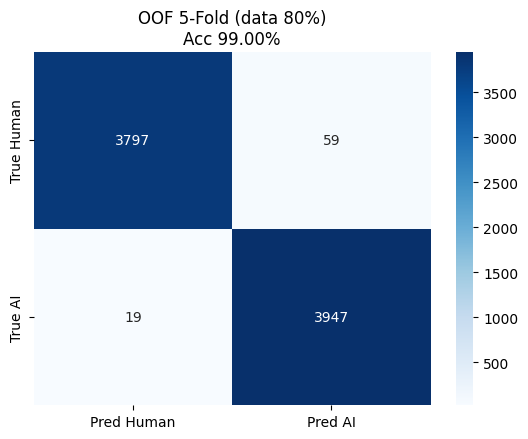

Akurasi per sumber:
                       mean   sum  count
label source                            
0     medium         0.9763  2263   2318
      wikipedia      0.9974  1534   1538
1     Rotten_Tomato  0.9986  2089   2092
      WMT-16         0.9915  1858   1874



In [11]:
rows = []
for k in range(1, N_FOLDS+1):
    m = metrics(cv_out[k]['oof']['label'], cv_out[k]['oof']['prob_ai']); m['fold'] = k; rows.append(m)
cv_tab = pd.DataFrame(rows).set_index('fold')
print(cv_tab.round(4))
print('\nMean :'); print(cv_tab.drop(columns='n').mean().round(4).to_string())
print('\nStd  :'); print(cv_tab.drop(columns='n').std(ddof=0).round(4).to_string())
cv_tab.to_csv(f'{RES_DIR}/cv_per_fold.csv')

oof = pd.concat([cv_out[k]['oof'] for k in range(1, N_FOLDS+1)], ignore_index=True)
oof.to_csv(f'{RES_DIR}/oof_predictions.csv', index=False)
show_report('OOF 5-Fold (data 80%)', oof)

## STEP 11 - Test Independen: Ensemble 5 Model pada Test 20% (dites SEKALI)
Probabilitas kelima model dirata-ratakan (soft voting). Threshold tetap 0,5.

Tiap model tunggal pada test 20%:
      n     acc  macro_f1  prec_human  rec_human  prec_ai  rec_ai     auc
1  1956  0.9882    0.9882      0.9989     0.9772   0.9783  0.9990  0.9974
2  1956  0.9877    0.9877      0.9989     0.9761   0.9773  0.9990  0.9979
3  1956  0.9893    0.9893      0.9927     0.9855   0.9860  0.9929  0.9996
4  1956  0.9831    0.9831      0.9989     0.9668   0.9687  0.9990  0.9968
5  1956  0.9882    0.9882      1.0000     0.9761   0.9773  1.0000  0.9942

=== Test 20% Ensemble ===
              precision    recall  f1-score   support

   Human (0)     0.9989    0.9824    0.9906       964
      AI (1)     0.9831    0.9990    0.9910       992

    accuracy                         0.9908      1956
   macro avg     0.9910    0.9907    0.9908      1956
weighted avg     0.9909    0.9908    0.9908      1956



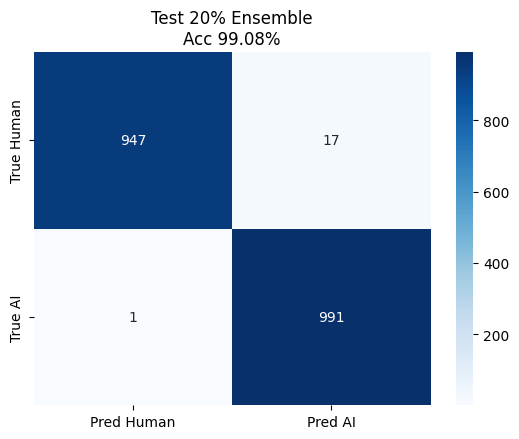

Akurasi per sumber:
                       mean  sum  count
label source                           
0     medium         0.9741  565    580
      wikipedia      0.9948  382    384
1     Rotten_Tomato  1.0000  523    523
      WMT-16         0.9979  468    469



In [12]:
# Dijalankan SEKALI; test 20% tidak dipakai untuk tuning apa pun.
test_probs = np.vstack([cv_out[k]['test20']['prob_ai'].values for k in range(1, N_FOLDS+1)])
base = cv_out[1]['test20']
for k in range(2, N_FOLDS+1):
    assert (cv_out[k]['test20']['orig_row'].values == base['orig_row'].values).all()
test_ens = base[['orig_id','orig_row','label','source']].copy(); test_ens['prob_ai'] = test_probs.mean(axis=0)
test_ens.to_csv(f'{RES_DIR}/test20_ensemble_predictions.csv', index=False)

single = pd.DataFrame([metrics(base['label'], test_probs[i]) for i in range(N_FOLDS)], index=range(1, N_FOLDS+1))
print('Tiap model tunggal pada test 20%:'); print(single.round(4)); print()
show_report('Test 20% Ensemble', test_ens)

## STEP 12 - Uji Lintas-Sumber (generalisasi ke sumber yang tidak pernah dilihat)
Arah 1: latih **Medium + Rotten_Tomato** → uji **Wikipedia + WMT-16**.
Arah 2: latih **Wikipedia + WMT-16** → uji **Medium + Rotten_Tomato**.
(Estimasi waktu: +/-15 menit per arah.)

Analisis tambahan: uji lintas-sumber (pelengkap, bukan hasil utama)

[xsrc_A_medium+RT_to_wiki+WMT] train=3,969 val=441 test=3,412


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
0,0.144900,0.117873,1.000000,1.000000
1,0.119900,0.117143,1.000000,1.000000
2,0.119800,0.117151,1.000000,1.000000


[xsrc_B_wiki+WMT_to_medium+RT] train=3,070 val=342 test=4,410


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.518800,0.135286,0.994152,0.994152
2,0.122800,0.128481,0.997076,0.997077
3,0.119200,0.127908,0.997076,0.997077
4,0.117200,0.128212,0.997076,0.997077


=== Lintas-Sumber 1 (medium+RT -> wiki+WMT) ===
              precision    recall  f1-score   support

   Human (0)     0.4769    0.9935    0.6445      1538
      AI (1)     0.9519    0.1057    0.1902      1874

    accuracy                         0.5059      3412
   macro avg     0.7144    0.5496    0.4173      3412
weighted avg     0.7378    0.5059    0.3950      3412



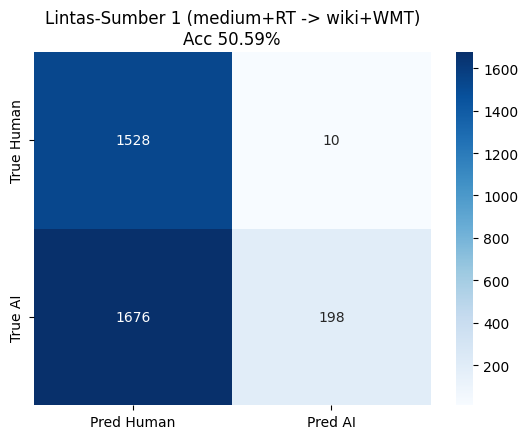

Akurasi per sumber:
                   mean   sum  count
label source                        
0     wikipedia  0.9935  1528   1538
1     WMT-16     0.1057   198   1874

=== Lintas-Sumber 2 (wiki+WMT -> medium+RT) ===
              precision    recall  f1-score   support

   Human (0)     1.0000    0.0375    0.0723      2318
      AI (1)     0.4839    1.0000    0.6522      2092

    accuracy                         0.4941      4410
   macro avg     0.7420    0.5188    0.3623      4410
weighted avg     0.7552    0.4941    0.3474      4410



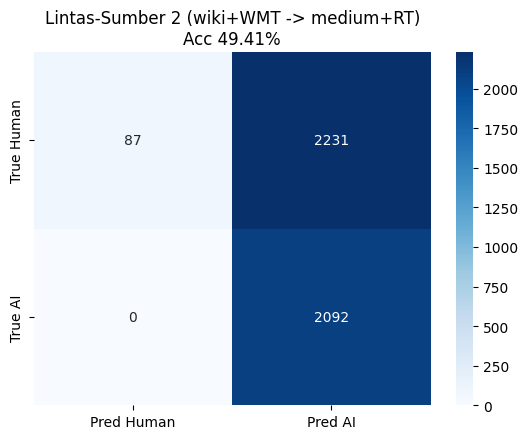

Akurasi per sumber:
                       mean   sum  count
label source                            
0     medium         0.0375    87   2318
1     Rotten_Tomato  1.0000  2092   2092



In [13]:
def cross_source(tag, train_src, test_src):
    # df = data 80% saja; df_test20 tidak disentuh
    pool = df[df['source'].isin(train_src)]
    tr, va = train_test_split(pool, test_size=VAL_RATIO, random_state=SEED, stratify=pool['strata'])
    te = df[df['source'].isin(test_src)]
    os.makedirs(f'{SPLIT_DIR}/xsrc_{tag}', exist_ok=True)
    for role, d in [('train', tr), ('val', va), ('test', te)]:
        d[['orig_id','orig_row','label','source','word_count','clean_text']].to_csv(f'{SPLIT_DIR}/xsrc_{tag}/{role}.csv', index=False)
    return run_experiment(f'xsrc_{tag}', tr, va, {'test': te})['test']

x1 = cross_source('A_medium+RT_to_wiki+WMT', ['medium','Rotten_Tomato'], ['wikipedia','WMT-16'])
x2 = cross_source('B_wiki+WMT_to_medium+RT', ['wikipedia','WMT-16'], ['medium','Rotten_Tomato'])
show_report('Lintas-Sumber 1 (medium+RT -> wiki+WMT)', x1)
show_report('Lintas-Sumber 2 (wiki+WMT -> medium+RT)', x2)

## STEP 13 - Ringkasan Akhir (untuk laporan)

In [14]:
def row(name, m): return {'Evaluasi': name, 'n': m['n'], 'Akurasi %': round(m['acc']*100,2), 'Macro-F1': round(m['macro_f1'],4),
        'Prec Human': round(m['prec_human'],4), 'Rec Human': round(m['rec_human'],4),
        'Prec AI': round(m['prec_ai'],4), 'Rec AI': round(m['rec_ai'],4), 'AUC': round(m['auc'],4)}
summ = [
    row('CV 5-fold OOF (data 80%)', metrics(oof['label'], oof['prob_ai'])),
    row('Test 20% - Ensemble 5 model', metrics(test_ens['label'], test_ens['prob_ai'])),
    row('Lintas-sumber 1: medium+RT -> wiki+WMT', metrics(x1['label'], x1['prob_ai'])),
    row('Lintas-sumber 2: wiki+WMT -> medium+RT', metrics(x2['label'], x2['prob_ai'])),
]
tab = pd.DataFrame(summ); print(tab.to_string(index=False)); tab.to_csv(f'{RES_DIR}/ringkasan_hasil.csv', index=False)

print(f"\nCV akurasi per fold: mean={cv_tab['acc'].mean()*100:.2f}% | std={cv_tab['acc'].std(ddof=0)*100:.2f} poin")
print('\nBaseline TF-IDF + LogReg (tanpa transformer):')
print(f'  tebak label (test 20%)       : {acc_tfidf_label*100:.2f}%')
print(f'  tebak sumber 4 kelas (test 20%): {acc_tfidf_src*100:.2f}%')
print(f'  lintas-sumber 1 / 2          : {acc_tfidf_x1*100:.2f}% / {acc_tfidf_x2*100:.2f}%')

                              Evaluasi    n  Akurasi %  Macro-F1  Prec Human  Rec Human  Prec AI  Rec AI    AUC
              CV 5-fold OOF (data 80%) 7822      99.00    0.9900      0.9950     0.9847   0.9853  0.9952 0.9983
           Test 20% - Ensemble 5 model 1956      99.08    0.9908      0.9989     0.9824   0.9831  0.9990 0.9999
Lintas-sumber 1: medium+RT -> wiki+WMT 3412      50.59    0.4173      0.4769     0.9935   0.9519  0.1057 0.8525
Lintas-sumber 2: wiki+WMT -> medium+RT 4410      49.41    0.3623      1.0000     0.0375   0.4839  1.0000 0.5532

CV akurasi per fold: mean=99.00% | std=0.15 poin

Baseline TF-IDF + LogReg (tanpa transformer):
  tebak label (test 20%)       : 91.92%
  tebak sumber 4 kelas (test 20%): 86.09%
  lintas-sumber 1 / 2          : 59.64% / 47.53%


## STEP 13B - Grafik & Kurva untuk Laporan
Sel-sel di bawah **hanya membaca file hasil yang sudah tersimpan** (`experiments/*/val_history.csv`, `pred_*.csv`), jadi **tidak perlu training ulang**. Cukup jalankan STEP 1-2 (import & konfigurasi) lalu sel-sel ini. Semua gambar disimpan ke `results/` (300 dpi) dan siap ditempel ke laporan.

| Gambar | Isi |
|---|---|
| `kurva_validasi_per_fold.png` | Kurva Loss / Akurasi / F1 validasi per epoch tiap fold (+ rata-rata) |
| `kurva_roc_pr.png` | Kurva ROC dan Precision-Recall (OOF, Test 20%, 2 lintas-sumber) |
| `akurasi_per_fold.png` | Akurasi & Macro-F1 tiap fold (+ mean +/- std) |
| `distribusi_probabilitas.png` | Sebaran P(AI) tiap kelas, memperlihatkan keyakinan model |
| `akurasi_per_sumber.png` | Akurasi per sumber data (Test 20% dan lintas-sumber) |

In [15]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── Setup grafik (aman dijalankan ulang; hanya membaca file hasil di disk) ─────────────────
    import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, accuracy_score
    try: N_FOLDS
    except NameError: N_FOLDS = 5
    try: THRESHOLD
    except NameError: THRESHOLD = 0.5
    try: EXP_DIR, RES_DIR
    except NameError:
        EXP_DIR, RES_DIR = '/kaggle/working/experiments', '/kaggle/working/results'
    # Cari folder experiments otomatis (jika hasil ada di tempat lain, mis. dataset input Kaggle)
    import glob
    if not os.path.exists(f'{EXP_DIR}/cv_fold1/pred_oof.csv'):
        _hit = glob.glob('/kaggle/**/cv_fold1/pred_oof.csv', recursive=True)
        if _hit:
            EXP_DIR = os.path.dirname(os.path.dirname(_hit[0])); print('EXP_DIR ditemukan di:', EXP_DIR)
        else:
            print('!! File hasil TIDAK ditemukan. Isi /kaggle/working:', os.listdir('/kaggle/working') if os.path.exists('/kaggle/working') else '-')
            print('!! Artinya hasil training sudah hilang (sesi di-reset). Upload folder experiments/ (atau tambahkan output notebook lama sebagai Input), lalu jalankan ulang sel ini.')
            raise FileNotFoundError('experiments/cv_fold*/pred_oof.csv tidak ada')
    os.makedirs(RES_DIR, exist_ok=True)

    plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                         'axes.spines.right': False, 'font.size': 11, 'axes.titleweight': 'bold'})
    COL = plt.cm.tab10.colors
    XSRC1 = 'xsrc_A_medium+RT_to_wiki+WMT'; XSRC2 = 'xsrc_B_wiki+WMT_to_medium+RT'

    def _rd(path):
        return pd.read_csv(path) if os.path.exists(path) else None

    oof_g   = pd.concat([d for d in (_rd(f'{EXP_DIR}/cv_fold{k}/pred_oof.csv') for k in range(1, N_FOLDS+1)) if d is not None], ignore_index=True)
    t20_all = [_rd(f'{EXP_DIR}/cv_fold{k}/pred_test20.csv') for k in range(1, N_FOLDS+1)]
    t20_all = [d for d in t20_all if d is not None]
    t20_g   = t20_all[0][['orig_id','orig_row','label','source']].copy()
    t20_g['prob_ai'] = np.mean([d['prob_ai'].values for d in t20_all], axis=0)      # ensemble (sama dgn STEP 11)
    x1_g, x2_g = _rd(f'{EXP_DIR}/{XSRC1}/pred_test.csv'), _rd(f'{EXP_DIR}/{XSRC2}/pred_test.csv')

    SETS = [('CV OOF (data 80%)', oof_g), ('Test 20% (ensemble)', t20_g),
            ('Lintas-sumber 1', x1_g), ('Lintas-sumber 2', x2_g)]
    SETS = [(n, d) for n, d in SETS if d is not None]
    print('Data tersedia:', [(n, len(d)) for n, d in SETS])
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


Data tersedia: [('CV OOF (data 80%)', 7822), ('Test 20% (ensemble)', 1956), ('Lintas-sumber 1', 3412), ('Lintas-sumber 2', 4410)]


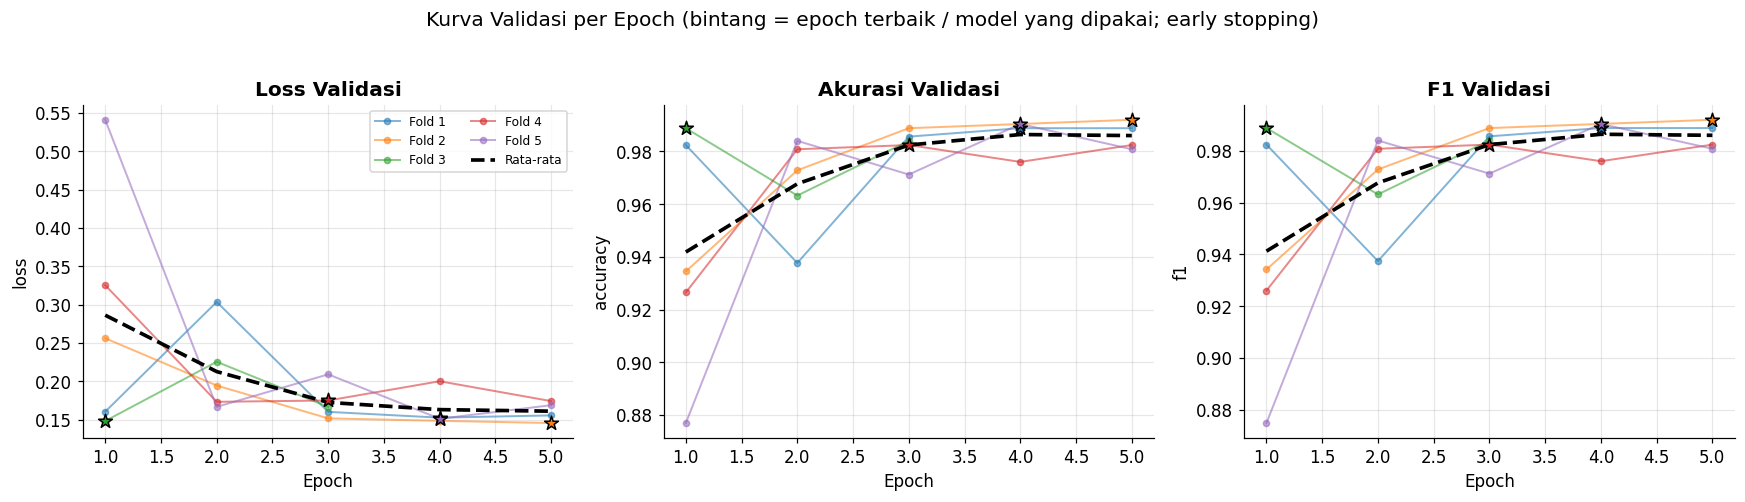

        Epoch terbaik  Val loss  Val acc  Val F1
Fold 1            4.0    0.1529   0.9888  0.9888
Fold 2            5.0    0.1459   0.9920  0.9920
Fold 3            1.0    0.1485   0.9888  0.9888
Fold 4            3.0    0.1753   0.9824  0.9824
Fold 5            4.0    0.1514   0.9904  0.9904


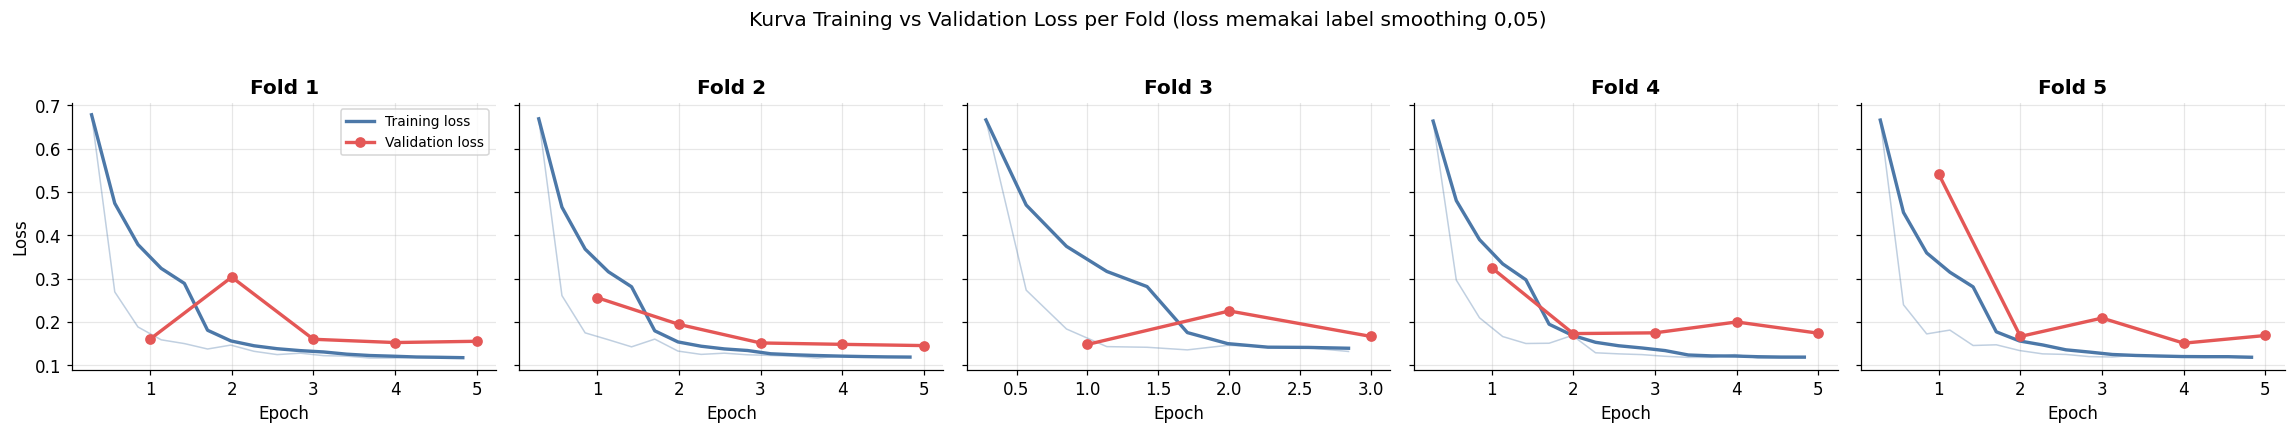

In [16]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── 1. Kurva validasi per epoch (Loss, Akurasi, F1) ─────────────────────────────────────────
    hist = {k: _rd(f'{EXP_DIR}/cv_fold{k}/val_history.csv') for k in range(1, N_FOLDS+1)}
    hist = {k: h for k, h in hist.items() if h is not None}
    metrics_plot = [('eval_loss', 'Loss Validasi'), ('eval_accuracy', 'Akurasi Validasi'), ('eval_f1', 'F1 Validasi')]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, (m, title) in zip(axes, metrics_plot):
        for k, h in hist.items():
            ax.plot(h['epoch'], h[m], marker='o', ms=4, lw=1.3, alpha=0.55, color=COL[k-1], label=f'Fold {k}')
            b = h.loc[h['eval_f1'].idxmax()]
            ax.scatter([b['epoch']], [b[m]], s=90, marker='*', color=COL[k-1], edgecolor='k', zorder=5)
        mx = max(len(h) for h in hist.values())
        avg = pd.concat(hist.values()).groupby(pd.concat(hist.values())['epoch'].round(0))[m].mean()
        ax.plot(avg.index, avg.values, 'k--', lw=2.4, label='Rata-rata')
        ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(m.replace('eval_', ''))
    axes[0].legend(fontsize=8, ncol=2)
    fig.suptitle('Kurva Validasi per Epoch (bintang = epoch terbaik / model yang dipakai; early stopping)', y=1.03)
    plt.tight_layout(); plt.savefig(f'{RES_DIR}/kurva_validasi_per_fold.png', dpi=300, bbox_inches='tight'); plt.show()

    # Ringkas: epoch terbaik tiap fold
    best = pd.DataFrame({f'Fold {k}': h.loc[h['eval_f1'].idxmax(), ['epoch','eval_loss','eval_accuracy','eval_f1']] for k, h in hist.items()}).T
    best.columns = ['Epoch terbaik', 'Val loss', 'Val acc', 'Val F1']
    print(best.round(4)); best.to_csv(f'{RES_DIR}/epoch_terbaik_per_fold.csv')

    # ── 1b. Kurva Training vs Validasi (loss) per fold: butuh log_history_full.csv (dibuat saat training) ──
    full = {k: _rd(f'{EXP_DIR}/cv_fold{k}/log_history_full.csv') for k in range(1, N_FOLDS+1)}
    full = {k: h for k, h in full.items() if h is not None and 'loss' in h.columns}
    if full:
        fig, axes = plt.subplots(1, len(full), figsize=(4.2*len(full), 3.8), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, (k, h) in zip(axes, full.items()):
            tr = h[h['loss'].notna()]; va = h[h['eval_loss'].notna()]
            ax.plot(tr['epoch'], tr['loss'], color='#4C78A8', alpha=0.35, lw=1)
            ax.plot(tr['epoch'], tr['loss'].rolling(5, min_periods=1).mean(), color='#4C78A8', lw=2.2, label='Training loss')
            ax.plot(va['epoch'], va['eval_loss'], 'o-', color='#E45756', lw=2.2, label='Validation loss')
            ax.set_title(f'Fold {k}'); ax.set_xlabel('Epoch')
        axes[0].set_ylabel('Loss'); axes[0].legend(fontsize=9)
        fig.suptitle('Kurva Training vs Validation Loss per Fold (loss memakai label smoothing 0,05)', y=1.03)
        plt.tight_layout(); plt.savefig(f'{RES_DIR}/kurva_train_vs_val_loss.png', dpi=300, bbox_inches='tight'); plt.show()
    else:
        print('log_history_full.csv belum ada (hasil dari run lama). Kurva training loss butuh training ulang dengan kode terbaru.')
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


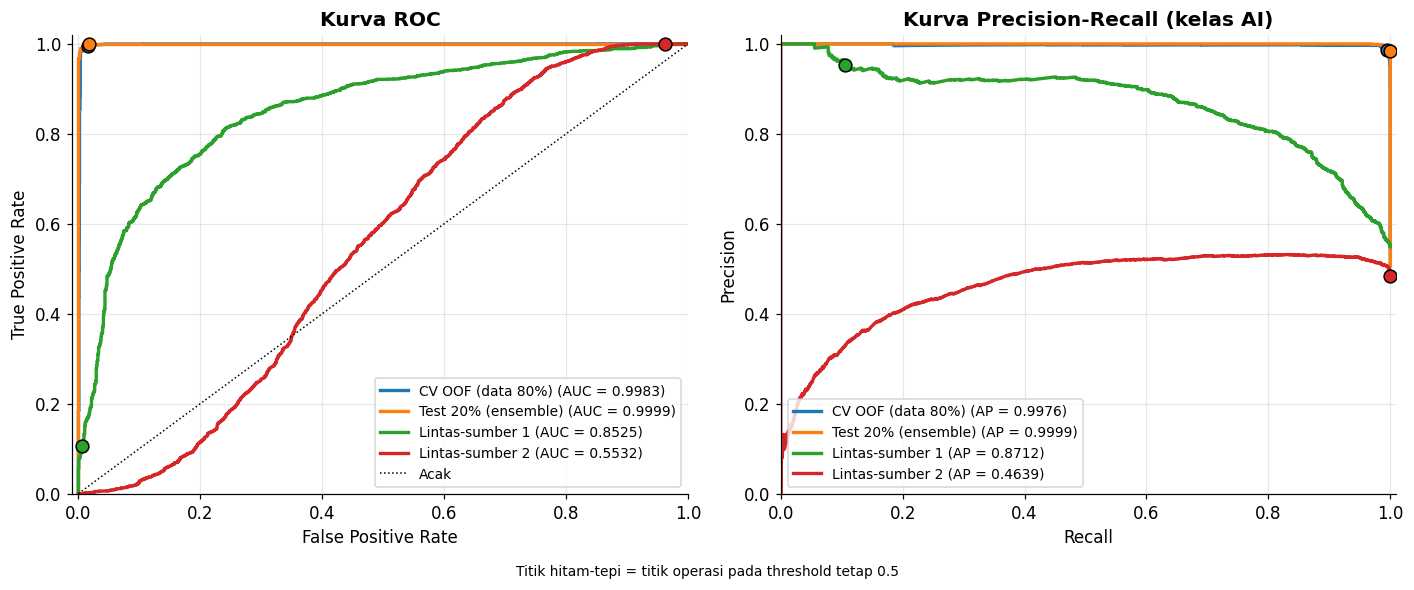

In [17]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── 2. Kurva ROC dan Precision-Recall ───────────────────────────────────────────────────────
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2))
    for i, (name, d) in enumerate(SETS):
        y, p = d['label'].values, d['prob_ai'].values
        fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        a1.plot(fpr, tpr, lw=2.2, color=COL[i], label=f'{name} (AUC = {auc(fpr, tpr):.4f})')
        a2.plot(rc, pr, lw=2.2, color=COL[i], label=f'{name} (AP = {average_precision_score(y, p):.4f})')
        # titik operasi pada threshold tetap 0,5
        pred = (p >= THRESHOLD).astype(int)
        tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
        fn = ((pred == 0) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
        a1.scatter([fp/max(fp+tn,1)], [tp/max(tp+fn,1)], s=70, color=COL[i], edgecolor='k', zorder=5)
        a2.scatter([tp/max(tp+fn,1)], [tp/max(tp+fp,1)], s=70, color=COL[i], edgecolor='k', zorder=5)
    a1.plot([0, 1], [0, 1], 'k:', lw=1, label='Acak'); a1.set_xlim(-0.01, 1); a1.set_ylim(0, 1.02)
    a1.set_title('Kurva ROC'); a1.set_xlabel('False Positive Rate'); a1.set_ylabel('True Positive Rate'); a1.legend(loc='lower right', fontsize=9)
    a2.set_title('Kurva Precision-Recall (kelas AI)'); a2.set_xlabel('Recall'); a2.set_ylabel('Precision')
    a2.set_xlim(0, 1.01); a2.set_ylim(0, 1.02); a2.legend(loc='lower left', fontsize=9)
    fig.text(0.5, -0.02, f'Titik hitam-tepi = titik operasi pada threshold tetap {THRESHOLD}', ha='center', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{RES_DIR}/kurva_roc_pr.png', dpi=300, bbox_inches='tight'); plt.show()
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


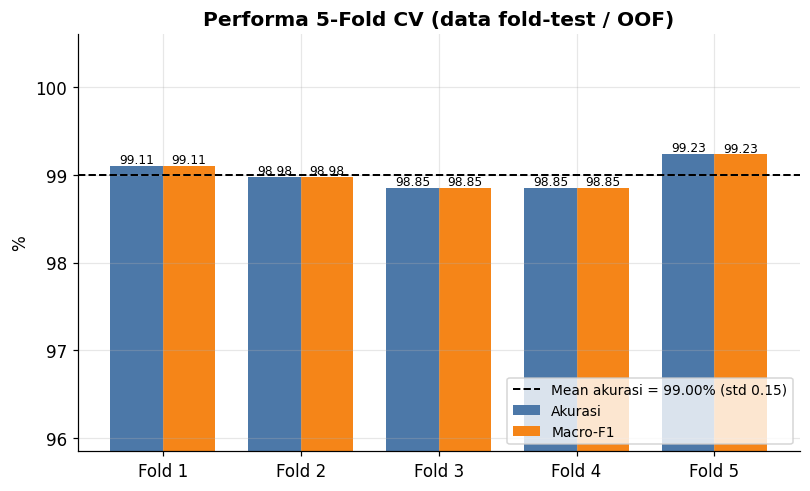

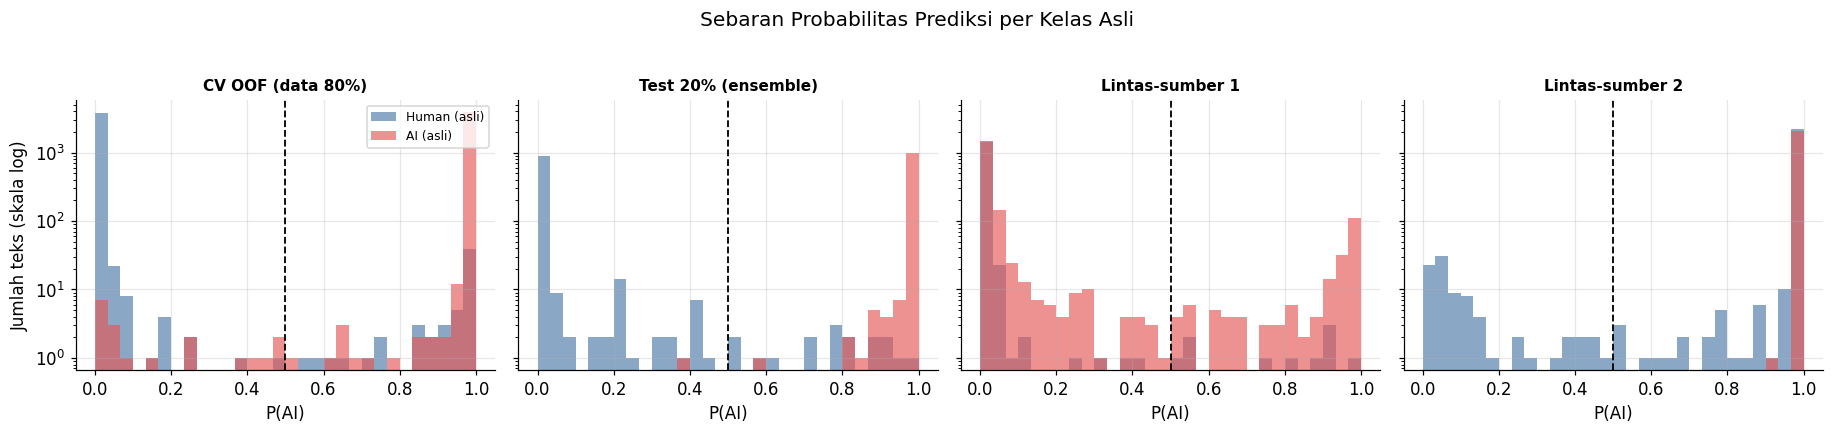

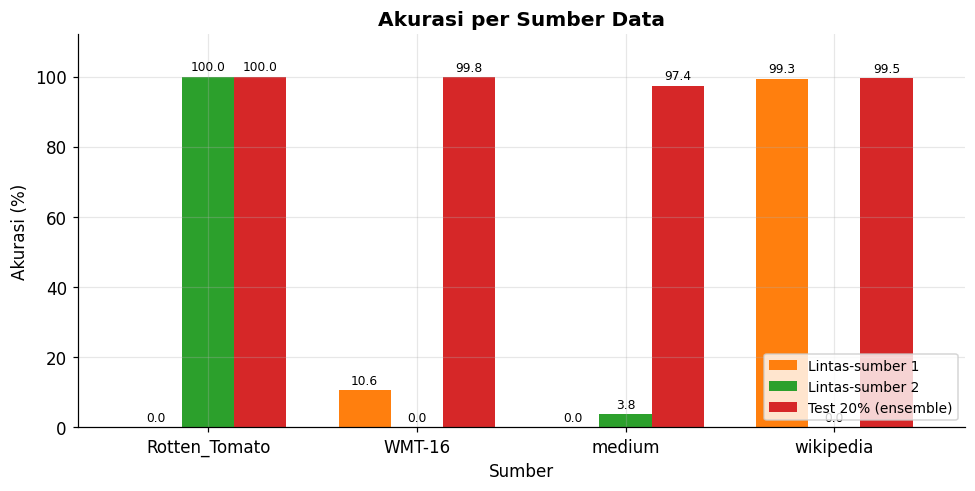

Evaluasi       Lintas-sumber 1  Lintas-sumber 2  Test 20% (ensemble)
Sumber                                                              
Rotten_Tomato              NaN           100.00               100.00
WMT-16                   10.57              NaN                99.79
medium                     NaN             3.75                97.41
wikipedia                99.35              NaN                99.48


In [18]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── 3. Akurasi per fold + sebaran probabilitas + akurasi per sumber ─────────────────────────
    from sklearn.metrics import f1_score
    fa, ff = [], []
    for k in range(1, N_FOLDS+1):
        d = _rd(f'{EXP_DIR}/cv_fold{k}/pred_oof.csv')
        if d is None: continue
        pr = (d['prob_ai'] >= THRESHOLD).astype(int)
        fa.append(accuracy_score(d['label'], pr)*100); ff.append(f1_score(d['label'], pr, average='macro')*100)
    ks = np.arange(1, len(fa)+1); w = 0.38
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    b1 = ax.bar(ks - w/2, fa, w, label='Akurasi', color='#4C78A8'); b2 = ax.bar(ks + w/2, ff, w, label='Macro-F1', color='#F58518')
    for b in list(b1) + list(b2): ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.03, f'{b.get_height():.2f}', ha='center', fontsize=8)
    ax.axhline(np.mean(fa), color='k', ls='--', lw=1.3, label=f'Mean akurasi = {np.mean(fa):.2f}% (std {np.std(fa):.2f})')
    lo = min(min(fa), min(ff)); ax.set_ylim(max(0, lo-3), 100.6)
    ax.set_xticks(ks); ax.set_xticklabels([f'Fold {k}' for k in ks]); ax.set_ylabel('%'); ax.set_title('Performa 5-Fold CV (data fold-test / OOF)')
    ax.legend(loc='lower right', fontsize=9); plt.tight_layout(); plt.savefig(f'{RES_DIR}/akurasi_per_fold.png', dpi=300); plt.show()

    fig, axes = plt.subplots(1, len(SETS), figsize=(4.2*len(SETS), 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (name, d) in zip(axes, SETS):
        ax.hist(d.loc[d['label'] == 0, 'prob_ai'], bins=30, range=(0, 1), alpha=0.65, color='#4C78A8', label='Human (asli)')
        ax.hist(d.loc[d['label'] == 1, 'prob_ai'], bins=30, range=(0, 1), alpha=0.65, color='#E45756', label='AI (asli)')
        ax.axvline(THRESHOLD, color='k', ls='--', lw=1.2); ax.set_yscale('log'); ax.set_title(name, fontsize=10); ax.set_xlabel('P(AI)')
    axes[0].set_ylabel('Jumlah teks (skala log)'); axes[0].legend(fontsize=8)
    fig.suptitle('Sebaran Probabilitas Prediksi per Kelas Asli', y=1.03)
    plt.tight_layout(); plt.savefig(f'{RES_DIR}/distribusi_probabilitas.png', dpi=300, bbox_inches='tight'); plt.show()

    rows = []
    for name, d in SETS:
        if name.startswith('CV'): continue
        t = d.assign(ok=((d['prob_ai'] >= THRESHOLD).astype(int) == d['label'])).groupby(['source'])['ok'].mean()*100
        for s, v in t.items(): rows.append({'Evaluasi': name, 'Sumber': s, 'Akurasi': v})
    ps = pd.DataFrame(rows).pivot(index='Sumber', columns='Evaluasi', values='Akurasi')
    ax = ps.plot(kind='bar', figsize=(9, 4.6), rot=0, color=COL[1:1+ps.shape[1]], width=0.75)
    for c in ax.containers: ax.bar_label(c, fmt='%.1f', fontsize=8, padding=2)
    ax.set_ylabel('Akurasi (%)'); ax.set_ylim(0, 112); ax.set_title('Akurasi per Sumber Data'); ax.legend(fontsize=9, loc='lower right')
    plt.tight_layout(); plt.savefig(f'{RES_DIR}/akurasi_per_sumber.png', dpi=300); plt.show()
    print(ps.round(2))
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


## STEP 13C - Ringkasan Visual & Penjelasan Akurasi (untuk screenshot laporan/sidang)
Menyatukan hasil RoBERTa, baseline TF-IDF, dan uji lintas-sumber dalam satu gambar + tabel + interpretasi otomatis. 
Jalankan setelah STEP 7 (agar angka baseline TF-IDF tersedia) dan sel setup STEP 13B.

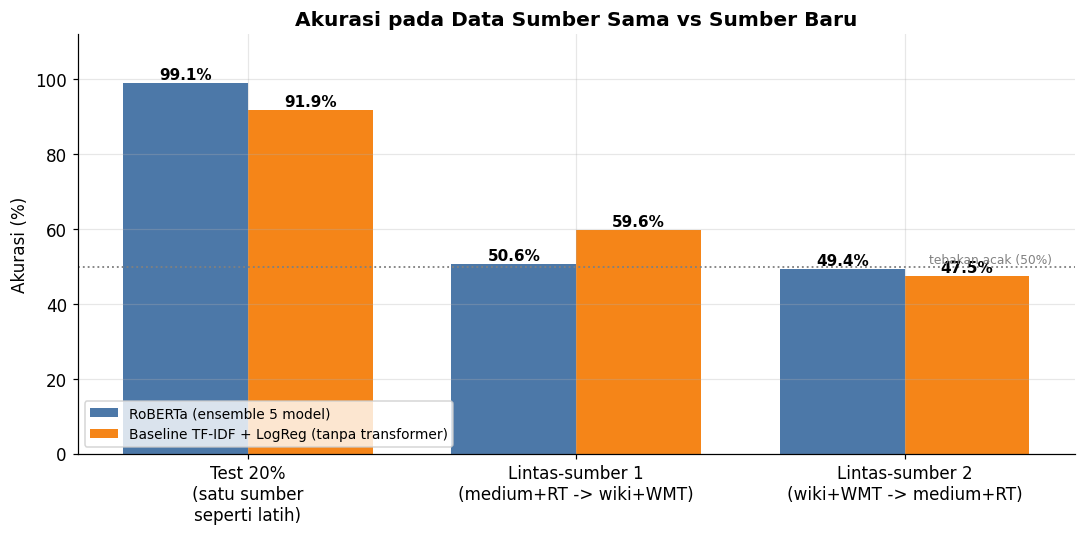

           Evaluasi    n  Akurasi %  Macro-F1  Prec AI  Rec AI    AUC
  CV OOF (data 80%) 7822      99.00    0.9900   0.9853  0.9952 0.9983
Test 20% (ensemble) 1956      99.08    0.9908   0.9831  0.9990 0.9999
    Lintas-sumber 1 3412      50.59    0.4173   0.9519  0.1057 0.8525
    Lintas-sumber 2 4410      49.41    0.3623   0.4839  1.0000 0.5532

INTERPRETASI (otomatis dari hasil)
1. Pada data uji 20% (sumber sama seperti data latih), RoBERTa mencapai 99.08%.
2. Baseline sederhana TF-IDF + Logistic Regression (tanpa transformer) sudah mencapai 91.92% pada test yang sama.
   Fitur yang sama dapat menebak SUMBER (4 kelas) dengan akurasi 86.09%.
   -> Tugas pada dataset ini relatif mudah karena gaya/topik tiap sumber sangat khas (mis. Wikipedia = Human, WMT-16 = AI).
3. Saat diuji pada sumber yang TIDAK pernah dilihat: 50.59% (arah 1) dan 49.41% (arah 2).
   -> Penurunan hingga 49.7 poin: akurasi tinggi sebagian besar berasal dari mengenali karakter sumber/domain,
      bukan semata pol

In [19]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── Ringkasan visual + penjelasan "kenapa akurasi tinggi" (siap screenshot untuk laporan / sidang) ──
    import matplotlib.pyplot as plt
    acc = lambda d: accuracy_score(d['label'], (d['prob_ai'] >= THRESHOLD).astype(int))*100
    A = {n: acc(d) for n, d in SETS}                               # RoBERTa: OOF, Test20, lintas-sumber 1 & 2
    g = globals()
    T = {'label': g.get('acc_tfidf_label'), 'x1': g.get('acc_tfidf_x1'), 'x2': g.get('acc_tfidf_x2'), 'src': g.get('acc_tfidf_src')}
    T = {k: (v*100 if v is not None else None) for k, v in T.items()}

    labels = ['Test 20%\n(satu sumber\nseperti latih)', 'Lintas-sumber 1\n(medium+RT -> wiki+WMT)', 'Lintas-sumber 2\n(wiki+WMT -> medium+RT)']
    rob = [A.get('Test 20% (ensemble)'), A.get('Lintas-sumber 1'), A.get('Lintas-sumber 2')]
    tfi = [T['label'], T['x1'], T['x2']]
    x = np.arange(3); w = 0.38
    fig, ax = plt.subplots(figsize=(10, 5))
    b1 = ax.bar(x - w/2, rob, w, color='#4C78A8', label='RoBERTa (ensemble 5 model)')
    b2 = ax.bar(x + w/2, [v if v is not None else 0 for v in tfi], w, color='#F58518', label='Baseline TF-IDF + LogReg (tanpa transformer)')
    for b in list(b1) + list(b2):
        if b.get_height() > 0: ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{b.get_height():.1f}%', ha='center', fontsize=10, fontweight='bold')
    ax.axhline(50, color='gray', ls=':', lw=1.2); ax.text(2.45, 51, 'tebakan acak (50%)', fontsize=8, color='gray', ha='right')
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 112); ax.set_ylabel('Akurasi (%)')
    ax.set_title('Akurasi pada Data Sumber Sama vs Sumber Baru'); ax.legend(loc='lower left', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{RES_DIR}/ringkasan_visual.png', dpi=300); plt.show()

    # Tabel ringkasan lengkap (dibaca dari prediksi tersimpan; threshold tetap 0,5)
    rows = []
    for n, d in SETS:
        y, p = d['label'].values, d['prob_ai'].values; pr = (p >= THRESHOLD).astype(int)
        pp, rr, ff, _ = precision_recall_fscore_support(y, pr, labels=[0,1], zero_division=0)
        fp_, tp_, _ = roc_curve(y, p)
        rows.append({'Evaluasi': n, 'n': len(y), 'Akurasi %': round(acc(d), 2), 'Macro-F1': round(ff.mean(), 4),
                     'Prec AI': round(pp[1], 4), 'Rec AI': round(rr[1], 4), 'AUC': round(auc(fp_, tp_), 4)})
    ring = pd.DataFrame(rows); print(ring.to_string(index=False)); ring.to_csv(f'{RES_DIR}/ringkasan_final.csv', index=False)

    # Penjelasan otomatis berdasarkan angka hasil (bukan teks tetap)
    t20, x1v, x2v = rob
    print('\n' + '='*88 + '\nINTERPRETASI (otomatis dari hasil)\n' + '='*88)
    print(f'1. Pada data uji 20% (sumber sama seperti data latih), RoBERTa mencapai {t20:.2f}%.')
    if T['label'] is not None:
        print(f'2. Baseline sederhana TF-IDF + Logistic Regression (tanpa transformer) sudah mencapai {T["label"]:.2f}% pada test yang sama.')
        if T['src'] is not None: print(f'   Fitur yang sama dapat menebak SUMBER (4 kelas) dengan akurasi {T["src"]:.2f}%.')
        print('   -> Tugas pada dataset ini relatif mudah karena gaya/topik tiap sumber sangat khas (mis. Wikipedia = Human, WMT-16 = AI).')
    print(f'3. Saat diuji pada sumber yang TIDAK pernah dilihat: {x1v:.2f}% (arah 1) dan {x2v:.2f}% (arah 2).')
    gap = max(t20 - min(x1v, x2v), 0.0)
    if gap > 15:
        print(f'   -> Penurunan hingga {gap:.1f} poin: akurasi tinggi sebagian besar berasal dari mengenali karakter sumber/domain,')
        print('      bukan semata pola "tulisan AI" yang berlaku umum. Ini keterbatasan dataset (label dan sumber saling terkait).')
    elif gap > 5:
        print(f'   -> Penurunan {gap:.1f} poin: model cukup menggeneralisasi, tetapi ada pengaruh karakter sumber.')
    else:
        print(f'   -> Penurunan hanya {gap:.1f} poin: model menggeneralisasi dengan baik ke sumber baru.')
    print('4. Bukti anti-kebocoran: data uji 20% dipisah total di awal, tanpa irisan ID/hash (STEP 4B & 6), threshold tetap 0,5,')
    print('   dan hasil didukung 5-fold CV (mean +/- std) sehingga bukan keberuntungan satu pembagian data.')
    print('='*88)
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


In [20]:
# _safe_wrapped: error di sel analisis TIDAK menggagalkan Save & Run All (hasil training tetap tersimpan)
import traceback
try:
    # ── Rekap file hasil (semua ada di /kaggle/working -> otomatis tersimpan di Output saat Save Version) ──
    import shutil
    zpath = shutil.make_archive(f'{WORKING_DIR}/hasil_grafik_dan_tabel', 'zip', RES_DIR)   # paket kecil: semua PNG + CSV hasil
    print('Paket hasil (grafik + tabel):', zpath, f'({os.path.getsize(zpath)/1e6:.1f} MB)\n')
    tot = 0
    for root, _, files in os.walk(WORKING_DIR):
        for fn in files: tot += os.path.getsize(os.path.join(root, fn))
    print(f'Total isi /kaggle/working: {tot/1e9:.2f} GB (batas output Kaggle 20 GB)')
    for d in ['results', 'split_data', 'experiments']:
        print(f'\n[{d}]', sorted(os.listdir(f'{WORKING_DIR}/{d}'))[:30])
except Exception:
    print('!! SEL INI ERROR (tidak menghentikan notebook):'); traceback.print_exc()


Paket hasil (grafik + tabel): /kaggle/working/hasil_grafik_dan_tabel.zip (1.7 MB)

Total isi /kaggle/working: 2.64 GB (batas output Kaggle 20 GB)

[results] ['akurasi_per_fold.png', 'akurasi_per_sumber.png', 'cm_Lintas-Sumber_1_(medium+RT_->_wiki+WMT).png', 'cm_Lintas-Sumber_2_(wiki+WMT_->_medium+RT).png', 'cm_OOF_5-Fold_(data_80%).png', 'cm_Test_20%_Ensemble.png', 'cv_per_fold.csv', 'distribusi_probabilitas.png', 'epoch_terbaik_per_fold.csv', 'kurva_roc_pr.png', 'kurva_train_vs_val_loss.png', 'kurva_validasi_per_fold.png', 'oof_predictions.csv', 'ringkasan_final.csv', 'ringkasan_hasil.csv', 'ringkasan_visual.png', 'test20_ensemble_predictions.csv']

[split_data] ['dev.csv', 'fold1', 'fold2', 'fold3', 'fold4', 'fold5', 'fold_roles.csv', 'split_config.json', 'split_manifest.csv', 'test20.csv', 'train80.csv', 'xsrc_A_medium+RT_to_wiki+WMT', 'xsrc_B_wiki+WMT_to_medium+RT']

[experiments] ['cv_fold1', 'cv_fold2', 'cv_fold3', 'cv_fold4', 'cv_fold5', 'xsrc_A_medium+RT_to_wiki+WMT', 'xsrc_B_w

## STEP 14 - Uji Teks Sendiri (ensemble model tersimpan)
Karena semua teks Wikipedia di data latih berlabel Human, model cenderung menganggap gaya Wikipedia = Human. Hasil lintas-sumber di STEP 12 menjelaskan hal ini.

In [21]:
def predict_text(texts, thr=THRESHOLD):
    cleaned = [preprocess_text(t) for t in texts]; probs = np.zeros(len(cleaned))
    for k in range(1, N_FOLDS+1):
        path = f'{EXP_DIR}/cv_fold{k}/model'
        if not os.path.isdir(path): continue
        tok = RobertaTokenizerFast.from_pretrained(path)
        mdl = RobertaForSequenceClassification.from_pretrained(path).to(device).eval()
        for i, t in enumerate(cleaned):
            enc = tok(t, return_tensors='pt', truncation=True, max_length=MAX_LENGTH).to(device)
            with torch.no_grad(): probs[i] += torch.softmax(mdl(**enc).logits.float(), -1)[0, 1].item()
        del mdl; gc.collect(); torch.cuda.empty_cache()
    probs /= N_FOLDS
    return [(p, 'AI' if p >= thr else 'Human') for p in probs]

contoh = ["Paste teks uji Anda di sini (minimal sekitar 50 kata)."]
for t, (p, l) in zip(contoh, predict_text(contoh)): print(f'{l} (P(AI)={p:.3f}) | {t[:80]}...')

AI (P(AI)=0.980) | Paste teks uji Anda di sini (minimal sekitar 50 kata)....


## Catatan untuk dilaporkan
- **Pembagian data:** `split_data/train80.csv`, `test20.csv`, `split_manifest.csv`, `fold_roles.csv`, `dev.csv`, `split_config.json`.
- **Data uji 20%** tidak dipakai untuk training, early stopping, fit TF-IDF, maupun penentuan threshold; dites satu kali dengan ensemble 5 model.
- Data dipisah 80%/20% di STEP 4B; 20% tersimpan di test20.csv dan dipakai sekali di STEP 11. Uji lintas-sumber di STEP 12 adalah analisis tambahan dan hanya memakai data 80%.
- **Audit kebocoran:** STEP 6. **Baseline & confound sumber:** STEP 7. **Generalisasi:** STEP 12.
- Interpretasi hasil lintas-sumber dan keterbatasan dataset (label dan sumber saling terkait) sebaiknya ditulis eksplisit di bab pembahasan.